# 14 · La distribución gaussiana multivariada

La densidad de un vector gaussiano, su gráfica en dos dimensiones, muestras en tres dimensiones y la estimación de parámetros por máxima verosimilitud.

Sea $X=(X_1,\dots,X_n)$ un vector gaussiano con media $\mu=(\mu_1,\dots,\mu_n)$ y matriz de covarianzas $\Sigma=(\operatorname{Cov}(X_i,X_j))_{i,j=1}^n$.

1. Cada componente $X_i$ es una variable normal $N(\mu_i,\Sigma_{ii})$.
2. Si las componentes son normales **independientes**, entonces $X$ es gaussiano, con $\Sigma$ diagonal.
3. Si $\mu\in\mathbb R^n$ y $\Sigma$ es simétrica y semidefinida positiva, **existe** un vector gaussiano con parámetros $\mu$ y $\Sigma$ (cuaderno 13).

Si además $\Sigma$ es definida positiva, $X$ tiene densidad

$$f(x;\mu,\Sigma)=\frac{1}{\sqrt{(2\pi)^n\det\Sigma}}\exp\left(-\frac12(x-\mu)^\top\Sigma^{-1}(x-\mu)\right),\qquad x\in\mathbb R^n.$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import cm
from scipy.stats import multivariate_normal

rng = np.random.default_rng(2026)

## 1. La densidad en dos dimensiones

In [2]:
mu = np.array([0.0, 1.0])
Sigma = np.array([[1.0, -0.5], [-0.5, 1.5]])
print("det Σ =", np.linalg.det(Sigma), "  valores propios:", np.linalg.eigvalsh(Sigma))

det Σ = 1.25   valores propios: [0.69098301 1.80901699]


Evaluamos la densidad en una malla. `np.einsum('...k,kl,...l->...', d, Σ⁻¹, d)` calcula la forma cuadrática $d^\top\Sigma^{-1}d$ en cada punto de la malla sin bucles.

In [3]:
def densidad_gaussiana(puntos, mu, Sigma):
    """Densidad N(mu, Sigma) evaluada en un arreglo de forma (..., n)."""
    n = mu.shape[0]
    d = puntos - mu
    forma = np.einsum("...k,kl,...l->...", d, np.linalg.inv(Sigma), d)
    return np.exp(-forma / 2) / np.sqrt((2 * np.pi) ** n * np.linalg.det(Sigma))


X, Y = np.meshgrid(np.linspace(-3, 3, 60), np.linspace(-3, 4, 60))
puntos = np.dstack([X, Y])        # forma (60, 60, 2)
Z = densidad_gaussiana(puntos, mu, Sigma)

print("coincide con scipy:", np.allclose(Z, multivariate_normal(mu, Sigma).pdf(puntos)))
print("integral numérica:", round(Z.sum() * (6 / 59) * (7 / 59), 4))

coincide con scipy: True
integral numérica: 0.9912


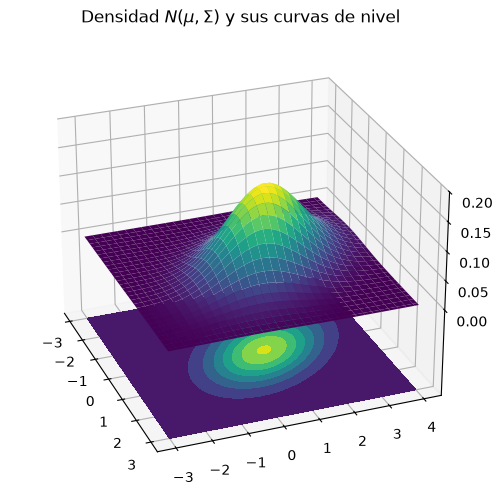

In [4]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Z, rstride=2, cstride=2, linewidth=0.3, antialiased=True, cmap=cm.viridis)
ax.contourf(X, Y, Z, zdir="z", offset=-0.15, cmap=cm.viridis)
ax.set_zlim(-0.15, 0.2)
ax.set_zticks(np.linspace(0, 0.2, 5))
ax.view_init(27, -21)
ax.set_title(r"Densidad $N(\mu,\Sigma)$ y sus curvas de nivel")
plt.show()

## 2. Muestras en tres dimensiones

Con $\mu=(2,-3,1)$ y

$$C=\begin{pmatrix}1&1&1\\1&3&2\\1&2&2\end{pmatrix}$$

(definida positiva), la matriz de diagramas de dispersión muestra las marginales normales en la diagonal y las proyecciones bidimensionales fuera de ella.

valores propios de C: [0.308  0.6431 5.0489]


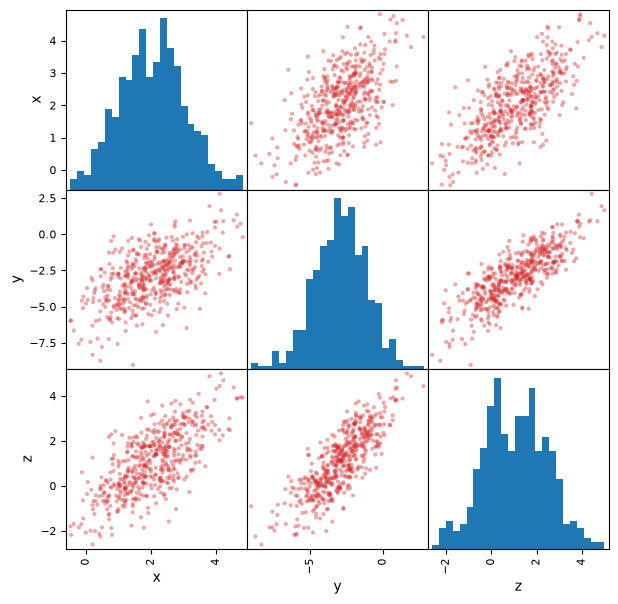

In [5]:
m = np.array([2, -3, 1])
C = np.array([[1, 1, 1], [1, 3, 2], [1, 2, 2]])
print("valores propios de C:", np.linalg.eigvalsh(C).round(4))

df = pd.DataFrame(rng.multivariate_normal(m, C, size=500), columns=["x", "y", "z"])
pd.plotting.scatter_matrix(df, color="tab:red", alpha=0.4, figsize=(7, 7), hist_kwds={"bins": 25})
plt.show()

La media y la covarianza muestrales se aproximan a $m$ y $C$:

In [6]:
display(df.mean().round(3).to_frame("media").T, df.cov().round(3))

,x,y,z
media,2.048,-2.902,1.08


,x,y,z
x,1.012,1.036,0.996
y,1.036,3.237,2.044
z,0.996,2.044,1.941


## 3. Estimación por máxima verosimilitud

Dadas observaciones independientes $x^{(1)},\dots,x^{(N)}$ de $N(\mu,\sigma^2)$, la log-verosimilitud es

$$\ell(\mu,\sigma)=-N\ln\sigma-\frac N2\ln(2\pi)-\frac{1}{2\sigma^2}\sum_{i=1}^N(x^{(i)}-\mu)^2.$$

Igualando a cero las derivadas parciales se obtienen los estimadores de máxima verosimilitud

$$\hat\mu=\frac1N\sum_i x^{(i)},\qquad \hat\sigma^2=\frac1N\sum_i\big(x^{(i)}-\hat\mu\big)^2,$$

la media y la varianza muestrales **dividiendo entre $N$** (`np.std` con `ddof=0`). En dimensión $n$, análogamente, $\hat\Sigma=\frac1N\sum_i(x^{(i)}-\hat\mu)(x^{(i)}-\hat\mu)^\top$.

La clase `Gaussiana` reúne densidad, muestreo y estimación.

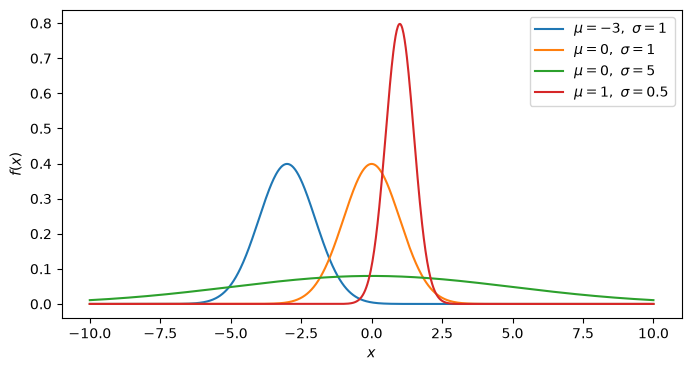

In [7]:
class Gaussiana:
    """Distribución normal univariada N(mu, sigma^2)."""

    def __init__(self, mu=0.0, sigma=1.0):
        self.mu, self.sigma = mu, sigma

    def densidad(self, x):
        return np.exp(-0.5 * ((x - self.mu) / self.sigma) ** 2) / (self.sigma * np.sqrt(2 * np.pi))

    def muestra(self, n):
        return self.mu + self.sigma * rng.standard_normal(n)

    def estima(self, x):
        """Estimadores de máxima verosimilitud."""
        self.mu, self.sigma = np.mean(x), np.std(x)
        return self

    def __repr__(self):
        return f"Gaussiana(mu={self.mu:.4f}, sigma={self.sigma:.4f})"


x = np.linspace(-10, 10, 1000)
fig, ax = plt.subplots(figsize=(8, 4))
for mu_, sigma_ in [(-3, 1), (0, 1), (0, 5), (1, 0.5)]:
    ax.plot(x, Gaussiana(mu_, sigma_).densidad(x), label=rf"$\mu={mu_},\ \sigma={sigma_}$")
ax.set_xlabel("$x$")
ax.set_ylabel("$f(x)$")
ax.legend()
plt.show()

In [8]:
verdadera = Gaussiana(2.0, 3.0)
for N in [10, 100, 1000, 100_000]:
    print(f"N = {N:>6}:", Gaussiana().estima(verdadera.muestra(N)))

N =     10: Gaussiana(mu=1.7362, sigma=2.6341)
N =    100: Gaussiana(mu=1.8048, sigma=3.0915)
N =   1000: Gaussiana(mu=1.8400, sigma=2.9674)
N = 100000: Gaussiana(mu=2.0016, sigma=2.9913)


## 4. Ejercicios

1. Calcula $\hat\Sigma$ para los datos de la sección 2 dividiendo entre $N$ y compárala con `df.cov()`, que divide entre $N-1$.
2. Demuestra que si $X\sim N(\mu,\Sigma)$ y $\Sigma=AA^\top$ con $A$ invertible, entonces $A^{-1}(X-\mu)\sim N(0,I)$, y que $(X-\mu)^\top\Sigma^{-1}(X-\mu)\sim\chi^2_n$.
3. Verifica el ejercicio anterior por simulación con los datos de la sección 2.